# Week 5: Neural Networks, Convolutions and Transfer Learning
**Project 2: Deep Learning Applications | Intel Image Classification (6 scene classes) | ResNet-18**


**Author**: Muhammad Umar Khan.  
**Date**:  17 October, 2026  
**Course**: Introduction to Applied AI


| Part | Topic |
|---|---|
| 1 | The data, GPU check, an image as numbers |
| 2 | Convolution, output size and parameter counts by hand |
| 3 | Transforms, augmentation and data loaders |
| 4 | Training loop and feature extraction (3,078 trainable parameters) |
| 5 | Fine-tuning `layer4` and learning curves |
| 6 | Test once, confusion matrix, error gallery, softmax |
| 7 | Save the model |

**Headline results (from this run):** feature extraction val accuracy **0.905**, fine-tuned val accuracy **0.933**, test accuracy **0.933** (2,798 of 3,000 images correct).

---
## Part 1: The Data and an Image as Numbers

### Task 1.1: Imports, GPU check and class counts

**What this cell does**
- Imports PyTorch, torchvision, NumPy, Matplotlib and scikit-learn metrics.
- Fixes the random seeds (`42`) so the train/validation split and training are reproducible.
- Picks the device: `cuda` if a GPU is available, otherwise `cpu`.
- Lists the 6 class folders (sorted alphabetically, which is also the label order `0..5`) and counts images per class.

**Class counts printed below**

| Class | Train | Test |
|---|---|---|
| buildings | 2,191 | 437 |
| forest | 2,271 | 474 |
| glacier | 2,404 | 553 |
| mountain | 2,512 | 525 |
| sea | 2,274 | 510 |
| street | 2,382 | 501 |
| **Total** | **14,034** | **3,000** |

Totals: $2191+2271+2404+2512+2274+2382 = 14{,}034$ training images and $437+474+553+525+510+501 = 3{,}000$ test images. The classes are fairly balanced (smallest 2,191, largest 2,512), so plain accuracy is a reasonable metric.

> **Note on the device:** this run printed `cpu`. Epochs took roughly 760 to 1,040 seconds. With the Kaggle accelerator set to GPU T4 the lab expects about 1 minute per epoch. Turn the GPU on before re-running.

In [66]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/umarkhan360/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cpu
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


### Task 1.2: Look at the images, then at the numbers

**What this cell does**
- Draws the first two images of each class in a $2 \times 6$ grid.
- Converts the last loaded image to a NumPy array and prints its shape, data type and value range.

**An image is a tensor of numbers**

$$\text{image} \in \{0,\dots,255\}^{H \times W \times C}, \qquad H = W = 150,\; C = 3$$

$$\text{numbers per image} = 150 \times 150 \times 3 = 67{,}500$$

`uint8` means each value is an unsigned 8-bit integer, so $2^8 = 256$ levels (0 = black, 255 = white). The three channels are Red, Green and Blue.

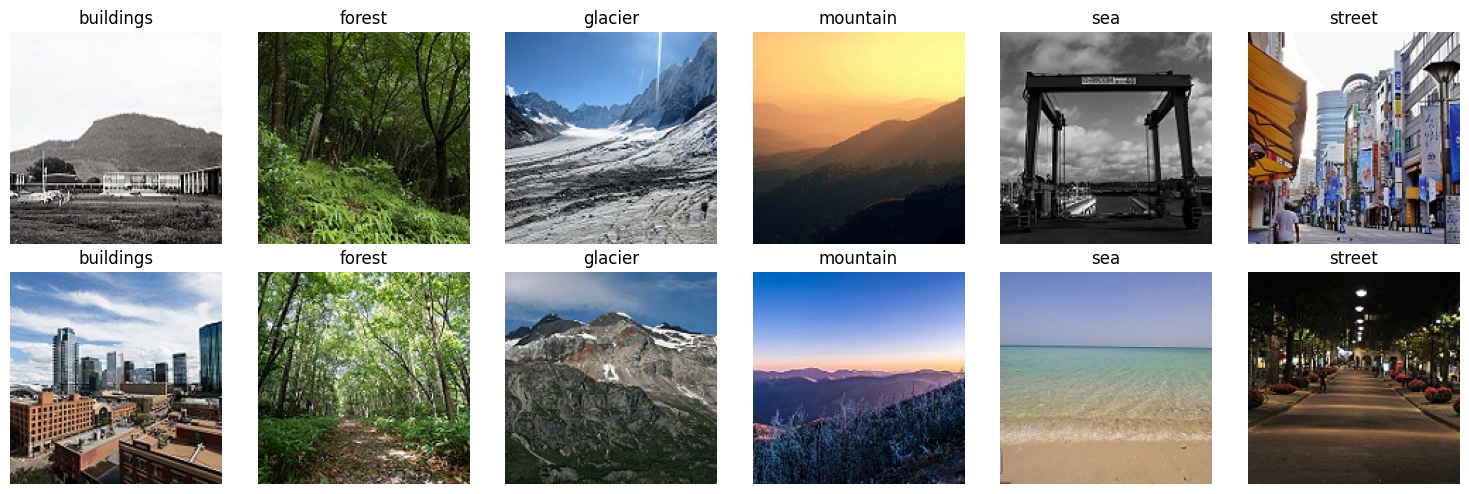

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [67]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### Write it: Part 1

**Most similar classes by eye:** *glacier* and *mountain* (snow-covered peaks look like glaciers and the reverse), and *buildings* and *street* (streets are lined with buildings). **My prediction:** the model will confuse **glacier vs mountain** most, with buildings vs street second. This is checked in Part 6.

**Image facts (printed above):**
- Shape (H, W, C) = **(150, 150, 3)**
- Data type = **uint8**
- Value range = **0 to 255**
- Top-left $3\times3$ of the red channel is `[[8,6,3],[6,5,4],[5,5,5]]`: very small numbers, so that corner is nearly black.

---
## Part 2: Convolution and Parameters by Hand

### Task 2.1: Reproduce the lecture's convolution (vertical edge)

**What this cell does**
- Builds the $5\times5$ lecture image (each row is `[0, 0, 10, 10, 10]`, so there is a vertical edge between columns 2 and 3) and the $3\times3$ kernel (each row `[-1, 0, 1]`).
- Applies `F.conv2d` and checks the output is three rows of `[30, 30, 0]`.
- Applies the same kernel to a real grayscale photo to show vertical edges.

**Convolution (cross-correlation) at one position**

$$y_{i,j} = \sum_{m=0}^{K-1}\sum_{n=0}^{K-1} x_{i+m,\,j+n}\; k_{m,n}$$

**Top-left output, by hand** (window = first three columns, `[0, 0, 10]` in every row):

Each row: $(-1)(0) + (0)(0) + (1)(10) = 10$

Three rows: $10 + 10 + 10 = \mathbf{30}$

**Right-most output** (window columns 3 to 5, all values 10): each row $(-1)(10)+(0)(10)+(1)(10) = 0$, so the total is $\mathbf{0}$. The flat region gives 0: the kernel responds only to the edge. This matches the printed tensor `[[30, 30, 0], ...]`.

**Output size:** $\frac{5-3+2(0)}{1}+1 = 3$, so the output is $3\times3$.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


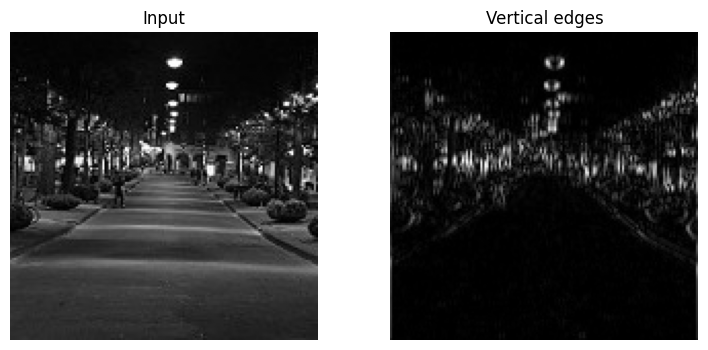

In [68]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

### Task 2.2: Why convolutions, in numbers

**What this cell does**
- Defines `count(m)`, the total number of parameters in a module.
- Compares a $3\times3$ convolution (3 to 64 channels) with a dense layer on the flattened image ($67{,}500 \to 512$).
- Checks the output size for stride 1 and stride 2, and for $2\times2$ max pooling.

**Parameter formulas**

$$\text{Conv parameters} = (K\cdot K\cdot C_{in} + 1)\cdot C_{out} \qquad\qquad \text{Dense parameters} = n_{in}\cdot n_{out} + n_{out}$$

**Convolution:** $(3\cdot3\cdot3+1)\cdot 64 = 28 \times 64 = \mathbf{1{,}792}$

**Dense:** $67{,}500 \times 512 + 512 = 34{,}560{,}000 + 512 = \mathbf{34{,}560{,}512}$

**Ratio:** $\dfrac{34{,}560{,}512}{1{,}792} = 19{,}286$, so the dense layer needs about **19,286 times** more parameters.

**Output size formula**

$$\text{out} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$

- Stride 1: $\frac{224-3+2}{1}+1 = 224$ (same size)
- Stride 2: $\left\lfloor\frac{224-3+2}{2}\right\rfloor+1 = \lfloor 111.5\rfloor + 1 = 112$ (halved)
- $2\times2$ max pool, stride 2: $224/2 = 112$, with **0 parameters**

These match the printed values.

In [69]:
def count(m):
    return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')  # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')  # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### Write it: Part 2

**Arithmetic.** Conv: $(3\times3\times3+1)\times64 = 28\times64 = 1{,}792$. Dense: $67{,}500\times512 + 512 = 34{,}560{,}512$. The dense layer needs $34{,}560{,}512 / 1{,}792 \approx$ **19,286 times** more parameters.

**Why weight sharing also helps recognise the same object in different places:** one small filter (27 weights per output channel) is slid over every position, so a pattern such as an edge or a window is detected wherever it appears, using the same weights. A dense layer would have to learn the same pattern separately for every position, which needs far more data and parameters, and it has no notion of neighbouring pixels.

---
## Part 3: Transforms and Data Loaders

### Task 3.1: Transforms, augmentation, and train/val/test loaders

**What this cell does**
- Defines the ImageNet normalisation statistics (the pretrained ResNet expects them).
- `train_tf`: random crop and resize to $224\times224$, random horizontal flip, mild brightness and contrast jitter, `ToTensor`, `Normalize`. **Augmentation is applied to training images only.**
- `eval_tf`: plain `Resize((224, 224))`, `ToTensor`, `Normalize` (no randomness) for validation and test.
- Opens the training folder **twice** (one view with augmentation, one clean) and splits both views with the **same random indices**, so validation images are never augmented and never overlap with training images.
- Builds three `DataLoader`s (batch sizes 64, 128, 128).

**Equations**

$$\text{ToTensor: } x \leftarrow \frac{x}{255} \in [0,1] \quad (\text{and } H{\times}W{\times}C \to C{\times}H{\times}W)$$

$$\text{Normalize: } x_c \leftarrow \frac{x_c - \mu_c}{\sigma_c},\quad \mu = [0.485, 0.456, 0.406],\; \sigma = [0.229, 0.224, 0.225]$$

After normalisation values lie roughly in $[-2, +2.6]$, the range the pretrained filters saw during ImageNet training.

**Split sizes**

$$n_{val} = \lfloor 0.15 \times 14{,}034 \rfloor = \lfloor 2{,}105.1 \rfloor = 2{,}105$$

$$n_{train} = 14{,}034 - 2{,}105 = 11{,}929, \qquad n_{test} = 3{,}000$$

**Why a validation set when a test set already exists?** Validation accuracy is used to choose the best epoch and to compare feature extraction with fine-tuning. The test set must play no part in any choice, so its score stays an honest estimate.

In [70]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


### Write it: Part 3

**Images per split:** **11,929 train | 2,105 validation | 3,000 test** (the first two come from the 14,034 training images, split 85% / 15%).

**Augmentation wrong for this dataset:** `RandomRotation(90)` or a vertical flip. A sea or a forest upside down (sky at the bottom) is not a realistic scene, and the "up" direction carries information (sky above, ground below), so the model would learn from images that never occur.

**Augmentation wrong for handwritten digits:** a horizontal flip or a 180 degree rotation. A flipped 2 looks like a 5 and a rotated 6 looks like a 9, so the label would no longer match the image.

---
## Part 4: The Training Loop and Feature Extraction

### Task 4.1: A reusable training loop

**What this cell does**
- `run_epoch` makes one pass over a loader. It trains only if an optimizer is passed in, and returns the average loss and the accuracy.
- `fit` repeats this for several epochs, records `(train loss, val loss, train acc, val acc)` in `history`, **remembers the weights from the best validation epoch**, reloads them at the end, and returns the best validation accuracy.

**The four steps of every training iteration**

| Step | Code | Math |
|---|---|---|
| Forward | `logits = model(xb)` | $z = f_\theta(x)$ |
| Loss | `F.cross_entropy(logits, yb)` | $L = -\log p_{\text{true}}$ |
| Backward | `loss.backward()` | $\dfrac{\partial L}{\partial w}$ by the chain rule |
| Step | `optimizer.step()` | $w \leftarrow w - \alpha\,\nabla_w L$ (Adam adapts $\alpha$ per weight) |

**Softmax and cross-entropy.** `F.cross_entropy` takes raw logits and applies softmax internally, so softmax is never applied twice:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}, \qquad L = -\log p_{\text{true}}$$

**Backpropagation** (chain rule): $\dfrac{\partial L}{\partial w} = \dfrac{\partial L}{\partial \hat y}\cdot\dfrac{\partial \hat y}{\partial z}\cdot\dfrac{\partial z}{\partial w}$

**Details.** `optimizer.zero_grad()` is called every batch because PyTorch accumulates gradients. `torch.set_grad_enabled(training)` turns gradients off for validation. `model.train()` or `model.eval()` is set by `model.train(training)`. The loss is weighted by batch size, `loss.item() * len(yb)`, so the epoch average is exact even when the last batch is smaller.

**Steps per epoch:** $\lceil 11{,}929 / 64 \rceil = 187$ gradient steps.

In [71]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n
def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

### Task 4.2: Freeze the body, train a new head (feature extraction)

**What this cell does**
- Loads ResNet-18 pretrained on ImageNet. The cell first tries the normal download (needs Internet On). If Internet is off, it falls back to the weights file added through *Add Input*.
- **Freezes** every pretrained parameter (`requires_grad = False`).
- Replaces the 1,000-class head with a new `Linear(512, 6)` for our 6 scene classes. New layers are trainable by default.
- Trains only the head for 3 epochs with Adam, $\text{lr}=10^{-3}$.

**Trainable parameters**

$$512 \times 6 + 6 = 3{,}072 + 6 = \mathbf{3{,}078}$$

**Total parameters:** $11{,}689{,}512 - (512\times1000 + 1000) + 3{,}078 = 11{,}179{,}590$ (printed above).

$$\frac{3{,}078}{11{,}179{,}590} = 0.0275\% \approx 0.03\%$$

**Results**

| Epoch | Train loss | Train acc | Val loss | Val acc |
|---|---|---|---|---|
| 1 | 0.601 | 0.807 | 0.331 | 0.895 |
| 2 | 0.339 | 0.885 | 0.309 | 0.895 |
| 3 | 0.308 | 0.892 | 0.274 | **0.905** |

Best validation accuracy with feature extraction: **0.905**.

In [72]:
import glob
try:
    # Needs Internet ON in the notebook settings
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
except Exception:
    # Internet OFF: use weights added via Add Input -> resnet18 (resnet18-f37072fd.pth)
    found = glob.glob('/kaggle/input/models/umarkhan360/resnet-18/pytorch/default/1/resnet18-f37072fd.pth', recursive=True)
    assert found, 'No weights found: turn Internet ON or Add Input -> resnet18'
    model = models.resnet18(weights=None)
    model.load_state_dict(torch.load(found[0], map_location='cpu'))
    print('Loaded offline weights from', found[0])
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
Loaded offline weights from /kaggle/input/models/umarkhan360/resnet-18/pytorch/default/1/resnet18-f37072fd.pth
Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.601 acc 0.807 | val loss 0.331 acc 0.895 (761s)
epoch 2: train loss 0.339 acc 0.885 | val loss 0.309 acc 0.895 (831s)
epoch 3: train loss 0.308 acc 0.892 | val loss 0.274 acc 0.905 (828s)
Best validation accuracy, feature extraction: 0.905


### Write it: Part 4

**Validation accuracy after each epoch:** epoch 1 = **0.895**, epoch 2 = **0.895**, epoch 3 = **0.905** (best, kept by `fit`). Validation loss fell steadily from 0.331 to 0.274.

**Why high accuracy is possible while training only 0.03% of the parameters:** the frozen body was trained on 1.2 million ImageNet photos and already computes a feature hierarchy: edges and colour blobs in early layers, textures in the middle, parts and whole-scene patterns in the last layers (slide 20). Those features are useful for almost any photo, including forests, glaciers and streets. The new head only has to learn how to combine the 512 pooled features into 6 scene labels, which a single linear layer ($512\times6+6 = 3{,}078$ parameters) can do well.

---
## Part 5: Fine-Tuning and Learning Curves

### Task 5.1: Unfreeze `layer4` with a smaller learning rate (fine-tuning)

**What this cell does**
- Unfreezes the last residual block, `layer4`, so its pretrained features can adapt to scene images.
- Creates a new Adam optimizer with **two learning rates** (discriminative learning rates):
  - `layer4`: $10^{-4}$ (gentle, because the weights are already good and large steps would destroy them: catastrophic forgetting)
  - `fc` head: $10^{-3}$ (ten times larger, because it is still close to random)
- Trains 3 more epochs. `history` keeps growing, so the plot in the next cell shows all 6 epochs.

**Trainable parameters now:** `layer4` has $8{,}393{,}728$ parameters, plus the head's $3{,}078$:

$$8{,}393{,}728 + 3{,}078 = \mathbf{8{,}396{,}806}$$

$$\frac{8{,}396{,}806}{11{,}179{,}590} = 75.1\% \quad(\text{three quarters of the network})$$

**Results**

| Epoch | Train loss | Train acc | Val loss | Val acc |
|---|---|---|---|---|
| 4 (fine-tune 1) | 0.260 | 0.906 | 0.213 | 0.926 |
| 5 (fine-tune 2) | 0.166 | 0.940 | 0.214 | 0.932 |
| 6 (fine-tune 3) | 0.120 | 0.956 | 0.208 | **0.933** |

Best validation accuracy, fine-tuned: **0.933**.

$$\Delta = 0.933 - 0.905 = +0.028 \;(\text{about } +2.8 \text{ percentage points})$$

In [73]:
for p in model.layer4.parameters():
    p.requires_grad = True                     # unfreeze the last block
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},  # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])     # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.260 acc 0.906 | val loss 0.213 acc 0.926 (1034s)
epoch 2: train loss 0.166 acc 0.940 | val loss 0.214 acc 0.932 (1035s)
epoch 3: train loss 0.120 acc 0.956 | val loss 0.208 acc 0.933 (1038s)
Best validation accuracy, fine-tuned: 0.933


### Task 5.2: Plot the learning curves

**What this cell does**
- Converts `history` to an array with columns `[train loss, val loss, train acc, val acc]`.
- Plots loss (left) and accuracy (right) against epoch for all 6 epochs. The dashed vertical line at $x = 3.5$ marks where fine-tuning begins.

**How to read the curves**
- Healthy learning: both training and validation loss fall.
- Overfitting: training loss keeps falling while validation loss flattens or rises.
- Here, from epoch 3 to 6 the training loss drops from 0.308 to 0.120, while the validation loss only goes from 0.274 to 0.208 and is flat across epochs 4 to 6 (0.213, 0.214, 0.208).

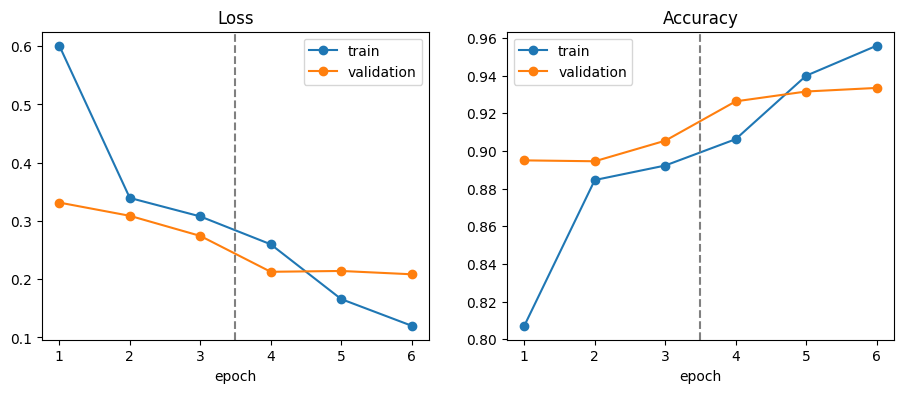

In [74]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

### Write it: Part 5

**Did fine-tuning help, and by how much?** Yes. Best validation accuracy rose from **0.905** (feature extraction) to **0.933** (fine-tuned), a gain of **+0.028**. Validation loss fell from 0.274 to 0.208.

**What the curves show:** in epochs 1 to 3 (head only) both losses fall. At epoch 4, when `layer4` is unfrozen, both drop again (val loss 0.274 to 0.213, val accuracy 0.905 to 0.926), so the adapted features help. After that, validation accuracy levels off at about 0.93 while training accuracy keeps climbing (0.906 to 0.956).

**Overfitting?** Only mild. Validation loss did not rise (0.213, 0.214, 0.208), but the gap between training loss (0.120) and validation loss (0.208) is widening, so it is close to the point where more epochs would start to overfit. Keeping the best epoch with `fit` protects against this.

**Why training accuracy can be lower than validation accuracy:** training images are augmented (random crops, flips, colour jitter), which makes them harder than the clean validation images. Also, training accuracy is averaged over the whole epoch while the weights are still changing, whereas validation is measured at the end of the epoch with the latest weights. In epochs 1 to 3, train accuracy (0.807, 0.885, 0.892) was below validation accuracy (0.895, 0.895, 0.905) for exactly these reasons.

---
## Part 6: Test Once, Then Study the Errors

### Task 6.1: Test-set evaluation (used once)

**What this cell does**
- Switches to `model.eval()` and runs the test loader with gradients off.
- Applies softmax to get class probabilities, takes the arg-max as the prediction, and computes accuracy, a classification report and a confusion matrix. The model was never tuned on this data.

**Metric definitions** (per class)

$$\text{precision} = \frac{TP}{TP+FP}, \qquad \text{recall} = \frac{TP}{TP+FN}, \qquad F_1 = \frac{2\cdot \text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

$$\text{accuracy} = \frac{\text{correct}}{\text{total}} = \frac{401+469+487+464+501+476}{3{,}000} = \frac{2{,}798}{3{,}000} = \mathbf{0.933}$$

**Confusion matrix (rows = true class, columns = predicted)**

| true \ pred | buildings | forest | glacier | mountain | sea | street |
|---|---|---|---|---|---|---|
| buildings | **401** | 0 | 0 | 1 | 1 | 34 |
| forest | 0 | **469** | 4 | 1 | 0 | 0 |
| glacier | 1 | 1 | **487** | 47 | 16 | 1 |
| mountain | 1 | 0 | 49 | **464** | 10 | 1 |
| sea | 1 | 0 | 5 | 2 | **501** | 1 |
| street | 24 | 0 | 0 | 0 | 1 | **476** |

**Worked example (glacier recall):** $\dfrac{487}{553} = 0.881$. **Recall by class:** forest 0.989, sea 0.982, street 0.950, buildings 0.918, mountain 0.884, glacier 0.881.

**Largest confusions:** glacier $\leftrightarrow$ mountain ($47 + 49 = 96$ errors), then buildings $\leftrightarrow$ street ($34 + 24 = 58$ errors). Together these two pairs make up $154$ of the $202$ total errors.

Test accuracy: 0.933
              precision    recall  f1-score   support

   buildings      0.937     0.918     0.927       437
      forest      0.998     0.989     0.994       474
     glacier      0.894     0.881     0.887       553
    mountain      0.901     0.884     0.892       525
         sea      0.947     0.982     0.964       510
      street      0.928     0.950     0.939       501

    accuracy                          0.933      3000
   macro avg      0.934     0.934     0.934      3000
weighted avg      0.932     0.933     0.932      3000



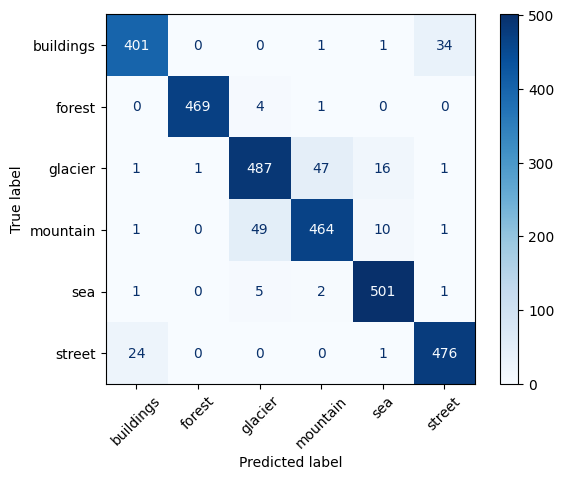

In [75]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

### Task 6.2: Error gallery

**What this cell does**
- Finds the indices where the prediction differs from the true label and shows the first 8 test images the model got wrong, with the true class, predicted class and softmax confidence in each title.
- The images are taken in dataset order, so most come from the first class (`buildings`) and this gallery is **not** a random sample of all errors.

**Confidence** is the largest softmax probability, $\max_k p_k$. Confident mistakes (for example 0.98 or 1.00) deserve the closest look, because they can mean either a mislabelled image or a genuine gap in the model.

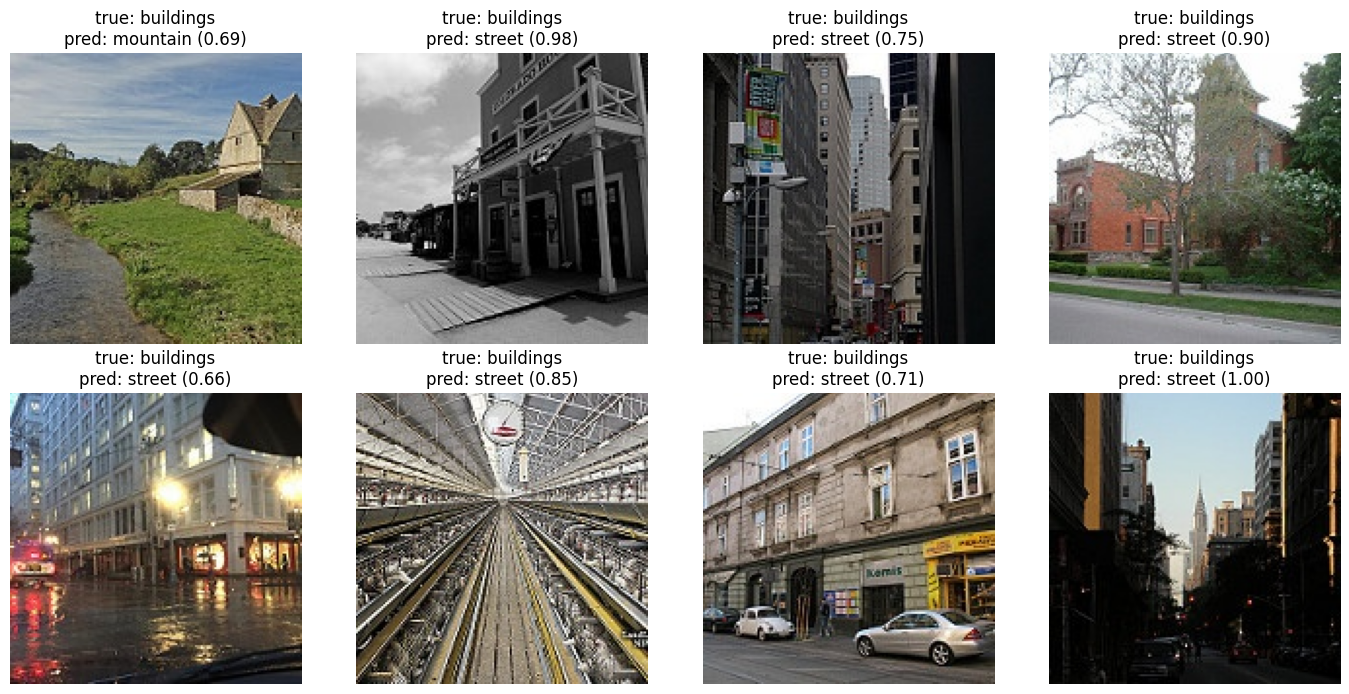

In [76]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

### Task 6.3: Inside one prediction (softmax by hand)

**What this cell does**
- Takes the first test image (true class: buildings), runs it through the model, and prints the 6 raw logits and their softmax probabilities.

**Softmax**

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{6} e^{z_j}}$$

**Check by hand** with the printed logits:

| Class | Logit $z$ | $e^{z}$ |
|---|---|---|
| buildings | 7.21 | 1352.9 |
| forest | -8.42 | 0.0002 |
| glacier | -4.16 | 0.0156 |
| mountain | -4.74 | 0.0087 |
| sea | -5.10 | 0.0061 |
| street | -1.86 | 0.1557 |
| **Sum** | | **1353.1** |

$$p_{\text{buildings}} = \frac{1352.9}{1353.1} = 0.9999 \approx 1.000$$

Loss for this image: $-\log(0.9999) \approx 0.0001$. The model is extremely confident and correct. The other five probabilities are all below 0.001, so they print as 0.000.

In [77]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   7.21   probability 1.000
forest     logit  -8.42   probability 0.000
glacier    logit  -4.16   probability 0.000
mountain   logit  -4.74   probability 0.000
sea        logit  -5.10   probability 0.000
street     logit  -1.86   probability 0.000


### Write it: Part 6

**Test accuracy:** **0.933** ($2{,}798/3{,}000$), the same as the best validation accuracy (0.933), so the validation estimate was reliable.

**Two weakest classes by recall:** **glacier** (0.881) and **mountain** (0.884).

**Most confused pair:** **glacier $\leftrightarrow$ mountain** (47 glaciers predicted as mountain and 49 mountains predicted as glacier, 96 errors in total). My prediction in Task 1.2 was glacier vs mountain, so it was **correct**. The second pair, buildings $\leftrightarrow$ street (34 + 24 = 58 errors), was also the second one I expected.

**Error gallery (first 8 errors, 7 of them buildings predicted as street):**
- *True buildings, predicted street (0.98), the grayscale wooden building:* the label is fine, but the picture shows a building facing a street, so the image is **genuinely ambiguous**. The model's confidence is too high for such a scene.
- *True buildings, predicted mountain (0.69), a stone house beside a river and hills:* the house is small and the scene is dominated by grass and hills, so the label is arguably the weak part and the image is **ambiguous**. The model's lower confidence reflects this.
- *True buildings, predicted street (1.00), a dark city canyon with a tower in the distance:* a street between tall buildings. The scene fits both labels, so it is **ambiguous** (the label could be either), not a clear model mistake.
- *True buildings, predicted street (0.85), the railway or industrial hall:* it does not look like a typical building exterior and the dominant structure is the track, so the **label is questionable**.

**Takeaway:** many remaining errors are scenes where two classes legitimately overlap, which is consistent with the lecture's note that errors above about 94% accuracy are mostly ambiguous or mislabelled images.

---
## Part 7: Save the Model

### Task 7: Save the weights

**What this cell does**
- Saves only the `state_dict` (the learned weights, not the Python class) to `/kaggle/working/resnet18_intel.pt`, and prints the file size: **44.8 MB**.

**Size check:** $11{,}179{,}590 \text{ parameters} \times 4 \text{ bytes (float32)} \approx 44.7 \text{ MB}$, which agrees with the printed 44.8 MB (the small difference is metadata and batch-norm buffers). This is well under GitHub's 100 MB file limit.

**To reload it later** (no internet needed):

```python
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 6)   # must match the saved head
model.load_state_dict(torch.load('/kaggle/working/resnet18_intel.pt', map_location='cpu'))
model.eval()
```

Use the same `eval_tf` transform and the same class order (`classes`) at prediction time.

In [78]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


---
## Check Your Understanding

### 1. Why does a network without nonlinear activations collapse to a single linear layer?

Without an activation function, each layer is just an affine map. Stack two of them:

$$h = W_1 x + b_1, \qquad \hat y = W_2 h + b_2$$

$$\hat y = W_2 (W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2) = W' x + b'$$

with $W' = W_2 W_1$ and $b' = W_2 b_1 + b_2$. The product of matrices is one matrix, so any number of layers equals a single linear layer. It can only draw straight-line boundaries and cannot learn features such as XOR. A nonlinearity such as ReLU, $\varphi(z)=\max(0,z)$, between the layers breaks this, so each layer can build new features from the previous ones.

### 2. For logits [3, 1, 0], what probability does softmax give the first class?

$$e^{3} = 20.0855,\qquad e^{1} = 2.7183,\qquad e^{0} = 1$$

$$\text{Sum} = 20.0855 + 2.7183 + 1 = 23.8038$$

$$p_1 = \frac{20.0855}{23.8038} = \mathbf{0.844}$$

For completeness, $p_2 = 2.7183/23.8038 = 0.114$ and $p_3 = 1/23.8038 = 0.042$, and $0.844+0.114+0.042 = 1.000$.

### 3. How many parameters does a 3 x 3 convolution from 64 to 128 channels have?

$$\text{params} = (K \cdot K \cdot C_{in} + 1)\cdot C_{out} = (3 \cdot 3 \cdot 64 + 1)\cdot 128 = (576 + 1)\cdot 128 = 577 \times 128 = \mathbf{73{,}856}$$

That is $576 \times 128 = 73{,}728$ weights plus $128$ biases.

### 4. An input of 56 x 56 goes through a 3 x 3 convolution with padding 1 and stride 2. What is the output size?

$$\text{out} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1 = \left\lfloor \frac{56 - 3 + 2}{2} \right\rfloor + 1 = \lfloor 27.5 \rfloor + 1 = 27 + 1 = \mathbf{28}$$

The output is $28 \times 28$ (the width and height are halved).

### 5. Why does a residual (skip) connection help gradients reach the early layers?

A residual block computes $y = F(x) + x$. Differentiating:

$$\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + 1$$

The "+ 1" is the identity path. Through $L$ blocks the gradient is a product of terms of the form $\left(1 + \frac{\partial F_i}{\partial x}\right)$, which always contains a direct route with a factor of 1, so it cannot shrink to zero just because the individual $\partial F_i/\partial x$ terms are small. In a plain deep stack the gradient is a product of many numbers below 1 (for example, a sigmoid derivative is at most 0.25, and $0.25^{20} \approx 9\times10^{-13}$), which vanishes before reaching the early layers. A block also only has to learn a correction $F(x)$, and if nothing helps it can learn $F = 0$ and pass the input unchanged. This is why networks with 100+ layers became trainable.

### 6. When would you train a CNN from scratch instead of using transfer learning?

Train from scratch when pretrained ImageNet features are unlikely to help or are not available:
- **Very large labelled dataset** (hundreds of thousands of images or more), so there is enough data to learn every filter without overfitting.
- **Images very unlike everyday photos**, for example radar, spectrograms, microscopy or other sensor data, where ImageNet edges and textures are not a good starting point.
- **Different input format**, such as a very different number of channels or image size, or a need for a custom or much smaller architecture (for example, for an embedded device).

With little data and photo-like images, as in this lab (about 14,000 images, 6 scene classes), transfer learning is the better choice: $3{,}078$ new parameters on top of good features is far less prone to overfitting than training $11.2$ million parameters from scratch.